# 03 · Embeddings to a held-out classification map

Install from the repository: `python -m pip install -e ".[demo,aef]"`.
Python 3.12+, CPU. Run all cells in order. All paths below are relative.
The small real data are bundled and SHA-256 checked by `load_demo`; corruption
raises an error. No Earth Engine login or manuscript workspace is needed.
[Full tutorial](https://github.com/GISWLH/earth-embedding/blob/main/docs/tutorials/real-demos.md).
Expected time: under one minute. Download: 0 bytes. Source: San Francisco Bay
Area, 5933 official 1280 m AEF **2021** overview cells and ESA WorldCover
**2021 v200** grouped dominant labels (both CC-BY-4.0; see bundled provenance).
Reference labels aggregate native 10 m pixel centers inside each AEF polygon.
This is a software teaching example, **not reproduction of the current global
paper benchmark**. It does not add any model to the frozen 20-system study.

The split was fixed before evaluation: south (maxlat <=37.88) trains, north
(minlat >=37.93) tests, with at least about 5.5 km between footprints.
3383 train / 2173 test / 375 buffer cells; two bare cells are excluded.
The four classes are built, vegetation, cropland and water. Only nine training
cells are cropland: this geographic class imbalance is retained, not resampled.
No parameter selection or test-label tuning: StandardScaler + LogisticRegression(C=1, tol=1e-8, seed=42).
Training uses float64 and a strict convergence tolerance for numerical reproducibility.

In [1]:
%matplotlib inline
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
from earth_embedding.demo import load_demo, pca_colors, plot_map
out = Path("outputs")
out.mkdir(exist_ok=True)
print("CPU demo; outputs are saved in ./outputs")
import json
from earth_embedding.demo import classify_demo, plot_classification

CPU demo; outputs are saved in ./outputs


In [2]:
bayarea = load_demo("bayarea")
result = classify_demo(bayarea)
display(__import__("pandas").crosstab(result["samples"].demo_split, result["samples"].class_name))
print(json.dumps(result["metrics"], indent=2))

class_name,bare,built,cropland,vegetation,water
demo_split,,,,,
buffer,0,44,28,254,49
excluded_other_class,2,0,0,0,0
test,0,249,239,1292,393
train,0,695,9,1864,815


{
  "scope": "San Francisco Bay Area regional software demonstration; not a paper benchmark reproduction",
  "seed": 42,
  "estimator": {
    "name": "StandardScaler + LogisticRegression",
    "C": 1.0,
    "tol": 1e-08,
    "max_iter": 2000,
    "dtype": "float64",
    "solver": "lbfgs"
  },
  "model": "AEF 2021 official 1280m overview features",
  "total": 5933,
  "split_counts": {
    "train": 3383,
    "test": 2173,
    "buffer": 375,
    "excluded_other_class": 2
  },
  "class_counts": {
    "buffer": {
      "bare": 0,
      "built": 44,
      "cropland": 28,
      "vegetation": 254,
      "water": 49
    },
    "excluded_other_class": {
      "bare": 2,
      "built": 0,
      "cropland": 0,
      "vegetation": 0,
      "water": 0
    },
    "test": {
      "bare": 0,
      "built": 249,
      "cropland": 239,
      "vegetation": 1292,
      "water": 393
    },
    "train": {
      "bare": 0,
      "built": 695,
      "cropland": 9,
      "vegetation": 1864,
      "water": 815
 

In [3]:
train = result["samples"].demo_split.eq("train").to_numpy()
np.testing.assert_allclose(result["estimator"].named_steps["standardscaler"].mean_, bayarea.features[train].mean(axis=0, dtype=np.float64))
assert result["samples"].loc[~result["samples"].demo_split.eq("test"), "prediction"].isna().all()
print("Scaler fitted on train only; predictions and metrics restricted to held-out north.")

Scaler fitted on train only; predictions and metrics restricted to held-out north.


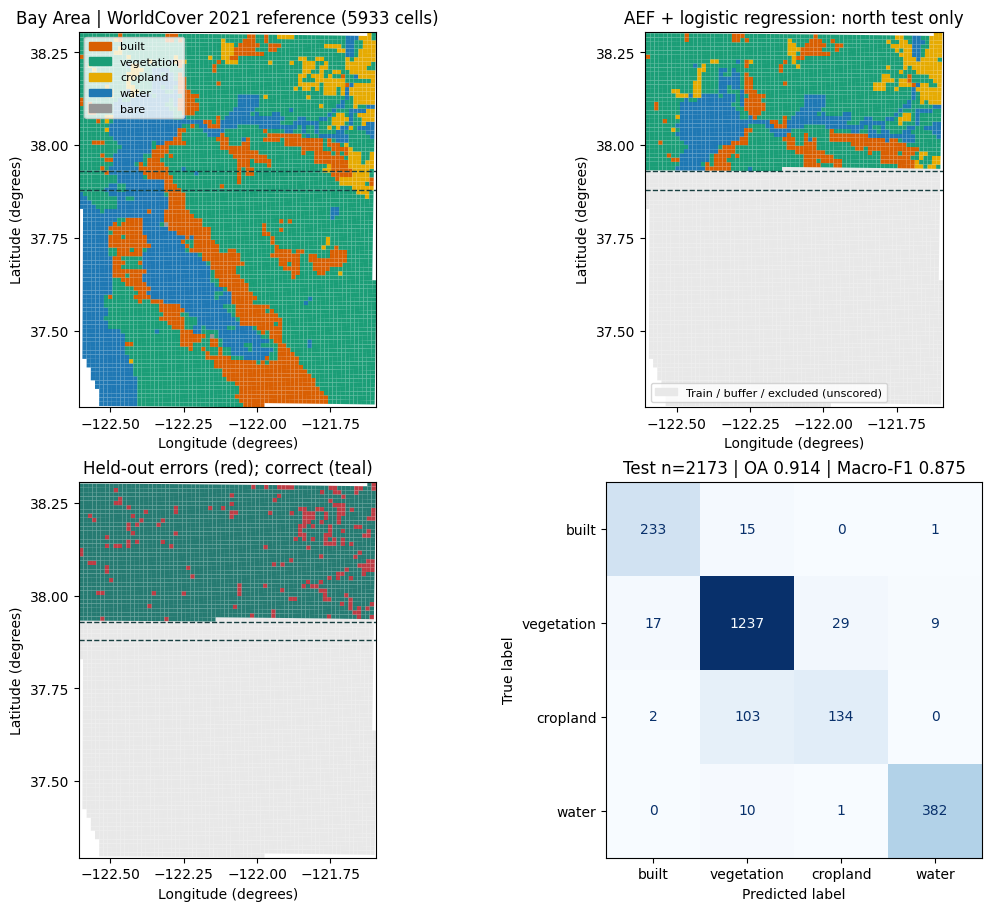

In [4]:
fig = plot_classification(result)
fig.savefig(out / "bayarea-classification.png", dpi=160)
result["samples"].to_csv(out / "predictions.csv", index=False)
(out / "metrics.json").write_text(json.dumps(result["metrics"], indent=2))
plt.show()

Gray areas have no held-out prediction. Red errors and confusion-matrix
rows compare predictions to WorldCover reference labels, not field-survey truth.
OA is overall accuracy; Macro-F1 gives each of the four classes equal weight;
Balanced Accuracy is mean per-class recall. One regional holdout has no uncertainty
estimate or global generalization claim. Same-year input and reference products
may share satellite signals; the buffer reduces immediate adjacency leakage,
but does not remove all spatial autocorrelation.